# Residual super-resolution on image patches

Can a small residual network improve bicubic reconstruction of downsampled patches?

I use non-overlapping patches from the camera image and split them by vertical regions. The residual network learns corrections to bicubic interpolation. This uses the super-resolution topic from HSE's adversarial laboratory without adding an adversarial loss.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "11_super_resolution"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Region-separated patches

The camera image is one measured scene, so this is a within-scene experiment. Training uses the top half, validation the next quarter and test the bottom quarter. Patches are disjoint and never cross a region boundary. Average pooling produces low-resolution inputs.

[128, 64, 64]


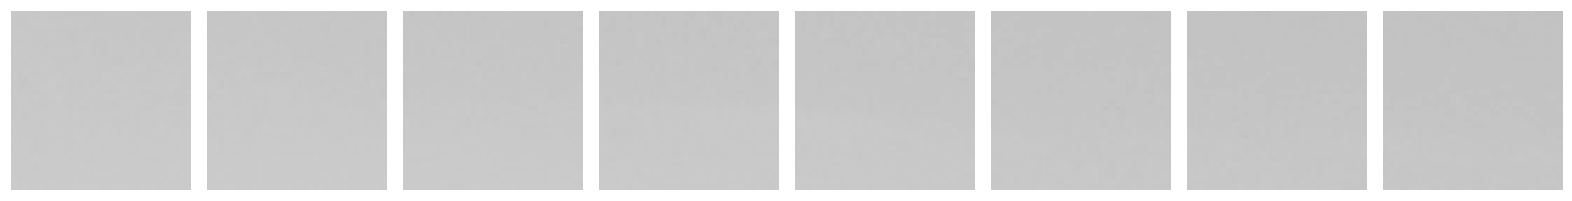

In [5]:
from skimage import data as sample_images
from vision_projects.models import SuperResolution

camera = torch.tensor(sample_images.camera() / 255, dtype=torch.float32)[None, None]
datasets = []
for region in [camera[..., :256, :], camera[..., 256:384, :], camera[..., 384:, :]]:
    high_resolution = region.unfold(2, 32, 32).unfold(3, 32, 32).reshape(-1, 1, 32, 32)
    low_resolution = F.avg_pool2d(high_resolution, 2)
    datasets.append(TensorDataset(low_resolution, high_resolution))
data = DataSplit(*datasets)
train_loader, validation_loader, test_loader = data.loaders(16)
print([len(dataset) for dataset in datasets])
image_grid(data.train.tensors[1][:8], output / "patches.png")

## Residual corrections

The prediction is $\hat{x}=U(y)+r_\theta(U(y))$, where $U$ is bicubic upsampling. Learning the residual lets the model start near a useful baseline. The network output is unconstrained during training; clamping is applied only as a specified display and evaluation convention.

class SuperResolution(nn.Module):
    def __init__(self):
        super().__init__()
        self.residual = nn.Sequential(
            nn.Conv2d(1, 24, 5, padding=2),
            nn.ReLU(),
            nn.Conv2d(24, 12, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(12, 1, 3, padding=1),
        )

    def forward(self, low_resolution):
        enlarged = F.interpolate(low_resolution, scale_factor=2, mode="bicubic", align_corners=False)
        return enlarged + self.residual(enlarged)



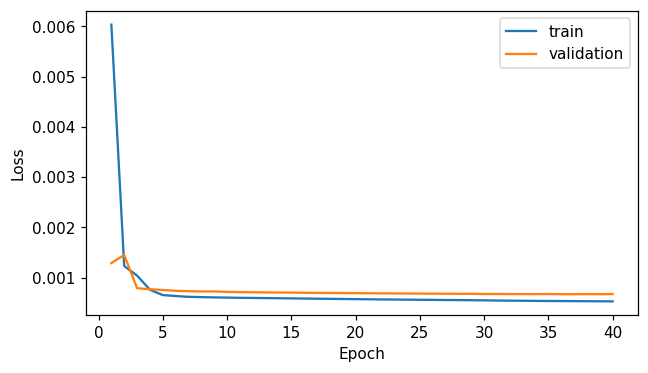

In [7]:
print(inspect.getsource(SuperResolution))
model = SuperResolution()
history = Trainer(
    model, nn.MSELoss(), TrainConfig(epochs=EPOCHS, learning_rate=0.001)
).fit(train_loader, validation_loader)
plot_history(history, output / "loss.png")
restored, target = predict(model, test_loader)
low = data.test.tensors[0]
bicubic = F.interpolate(low, scale_factor=2, mode="bicubic", align_corners=False)
nearest = F.interpolate(low, scale_factor=2, mode="nearest")

## PSNR and structural similarity

All methods are clipped to the same valid intensity range. SSIM uses a data range of one. I report global MSE and the mean patch SSIM, because they respond differently to small structural changes.

In [9]:
from skimage.metrics import structural_similarity

rows = []
for name, values in [
    ("nearest", nearest),
    ("bicubic", bicubic),
    ("residual_cnn", restored),
]:
    values = values.clamp(0, 1)
    mse = float(F.mse_loss(values, target))
    ssim = np.mean(
        [
            structural_similarity(a[0].numpy(), b[0].numpy(), data_range=1)
            for a, b in zip(values, target)
        ]
    )
    rows.append(
        {
            "method": name,
            "mse": mse,
            "psnr_db": float(-10 * np.log10(mse)),
            "ssim": float(ssim),
        }
    )
print(pd.DataFrame(rows))
results = {"test": rows, "scene_count": 1, "region_split": True}

         method       mse    psnr_db      ssim
0       nearest  0.002486  26.045185  0.754585
1       bicubic  0.002032  26.919861  0.748441
2  residual_cnn  0.001977  27.038844  0.762057


## Detail and residual maps

A residual map shows the learned correction, not an additional measurement of the scene. Sharper appearance can still disagree with the held-out target. The test region contains different local textures from the training region.

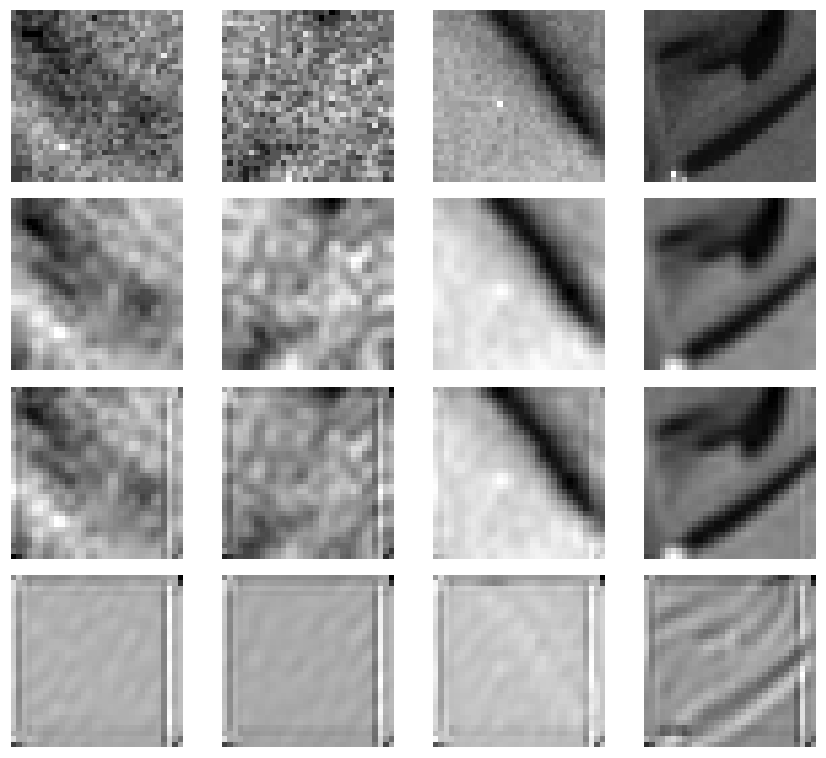

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(8, 7))
for row, images in enumerate(
    [target, bicubic, restored.clamp(0, 1), restored - bicubic]
):
    for column in range(4):
        axes[row, column].imshow(images[column, 0], cmap="gray")
        axes[row, column].axis("off")
fig.tight_layout()
fig.savefig(output / "detail.png", dpi=140)
plt.show()

## Reading the result

This score measures held-out regions of a single scene. It says little about generalization to new cameras or specimens. The comparison includes bicubic because the neural model explicitly learns a correction to it.

Recorded run: The scene-level split is intentionally limited to one camera image. Compare the rows printed above before attributing any gain to learned detail: the neural residual and interpolation baselines can differ by much less than one dB. The region split prevents identical patches from appearing in both training and test.

In [13]:
result_path = root / "results" / "11_super_resolution.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/11_super_resolution.json


## Next experiment

Use several independent images and split by image before cropping. Add a perceptual loss only after deciding how its reconstructed details will be evaluated.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week09_adversarial.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.